In [1]:
import os
import tensorflow as tf
import matplotlib.pyplot as plt
from keras.models import Sequential
from keras.layers import Flatten,Dense,Conv2D,MaxPooling2D,Input,Dropout


I0000 00:00:1793627102.669705   68659 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793627102.670698   68659 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793627102.872433   68659 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793627104.016460   68659 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

In [2]:
path = "/home/atharv/Downloads/DL/Pneumonia X Ray-20221031T100017Z-001/Pneumonia X Ray"

In [3]:
train=tf.keras.utils.image_dataset_from_directory(
    path + "/train",
    image_size=(150,150),
    batch_size=32,
    color_mode='grayscale',
    label_mode='binary'
)

Found 3937 files belonging to 2 classes.


E0000 00:00:1793627105.254974   68659 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1793627105.330064   68659 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


In [4]:
test=tf.keras.utils.image_dataset_from_directory(
    path + "/test",
    image_size=(150,150),
    batch_size=32,
    color_mode='grayscale',
    label_mode='binary'
)

Found 624 files belonging to 2 classes.


In [5]:
val=tf.keras.utils.image_dataset_from_directory(
    path + "/val",
    image_size=(150,150),
    batch_size=32,
    color_mode='grayscale',
    label_mode='binary'
)

Found 16 files belonging to 2 classes.


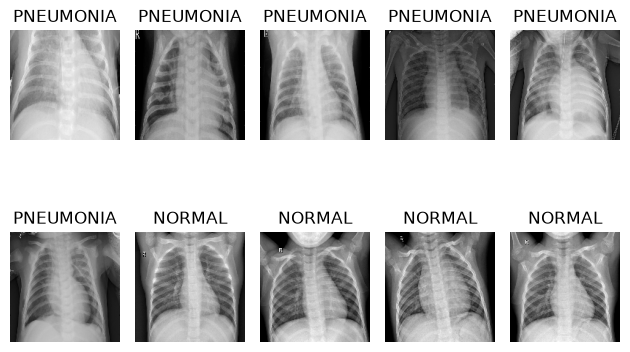

In [6]:
class_names = train.class_names

for images, labels in train.take(1):
    for i in range(10):
        plt.subplot(2, 5, i+1)
        plt.imshow(images[i].numpy().squeeze(), cmap='gray')
        plt.title(class_names[int(labels[i].numpy()[0])])
        plt.axis('off')
plt.tight_layout()
plt.show()

In [7]:
train=train.map(lambda x,y: (x/255.0, y))
test=test.map(lambda x,y: (x/255.0, y))

In [8]:
model=Sequential([
    Input(shape=(150,150,1)),
    Conv2D(32,(3,3),activation='relu'),
    MaxPooling2D(2,2),
    Conv2D(64,(3,3),activation='relu'),
    MaxPooling2D(2,2),
    Flatten(),
    Dense(128,activation='relu'),
    Dense(1,activation='sigmoid')
])

In [9]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [10]:
H=model.fit(
   train,
    epochs=5,
    validation_data=test
)

Epoch 1/5


/home/atharv/jupyter-env/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


124/124 ━━━━━━━━━━━━━━━━━━━━ 19s 148ms/step - accuracy: 0.8806 - loss: 0.3239 - val_accuracy: 0.6971 - val_loss: 1.0813
Epoch 2/5
124/124 ━━━━━━━━━━━━━━━━━━━━ 18s 145ms/step - accuracy: 0.9670 - loss: 0.0898 - val_accuracy: 0.7484 - val_loss: 1.0386
Epoch 3/5
124/124 ━━━━━━━━━━━━━━━━━━━━ 18s 146ms/step - accuracy: 0.9721 - loss: 0.0809 - val_accuracy: 0.7003 - val_loss: 1.5717
Epoch 4/5
124/124 ━━━━━━━━━━━━━━━━━━━━ 18s 147ms/step - accuracy: 0.9815 - loss: 0.0512 - val_accuracy: 0.7276 - val_loss: 1.3921
Epoch 5/5
124/124 ━━━━━━━━━━━━━━━━━━━━ 19s 149ms/step - accuracy: 0.9870 - loss: 0.0363 - val_accuracy: 0.7388 - val_loss: 1.2593


In [11]:
loss, acc = model.evaluate(test)

print("Test Accuracy:", acc)
print("Test Loss:", loss)

20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.7388 - loss: 1.2593
Test Accuracy: 0.7387820482254028
Test Loss: 1.2593168020248413


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step


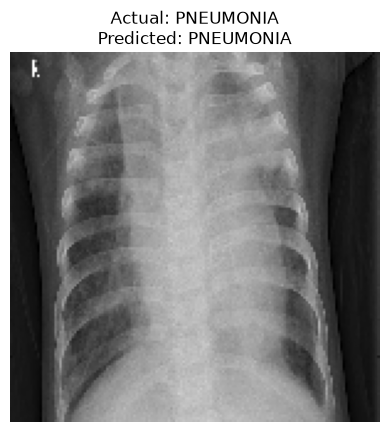

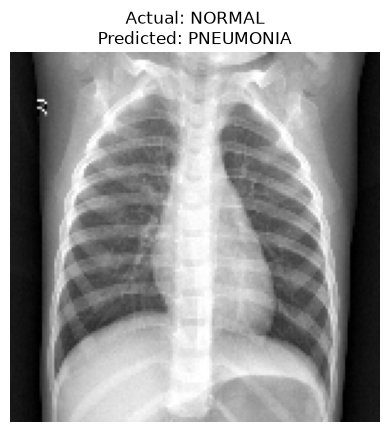

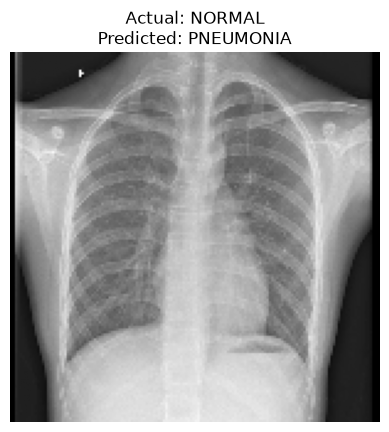

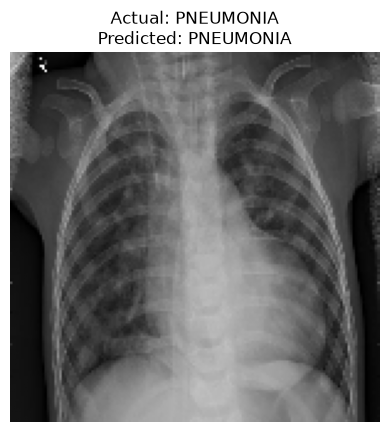

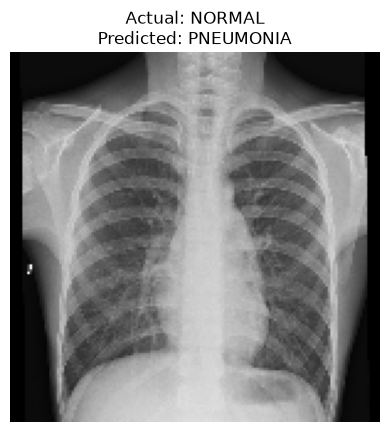

In [12]:
for images, labels in test.take(1):
    prediction = model.predict(images)
    for i in range(5):
        plt.imshow(images[i].numpy().squeeze(), cmap='gray')
        plt.title("Actual: " + class_names[int(labels[i][0].numpy())] +
                  "\nPredicted: " + class_names[int(prediction[i][0] > 0.5)])
        plt.axis('off')
        plt.show()

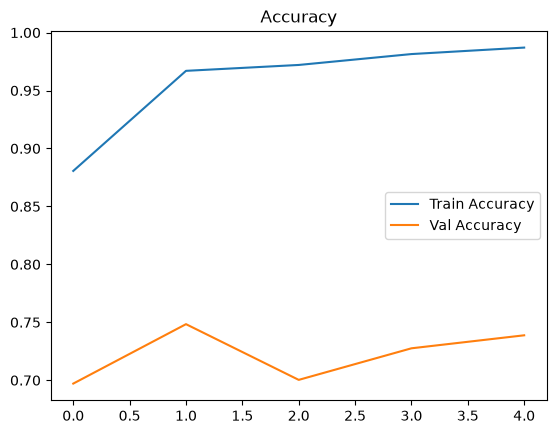

In [13]:
plt.plot(H.history['accuracy'], label='Train Accuracy')
plt.plot(H.history['val_accuracy'], label='Val Accuracy')
plt.title('Accuracy')
plt.legend()

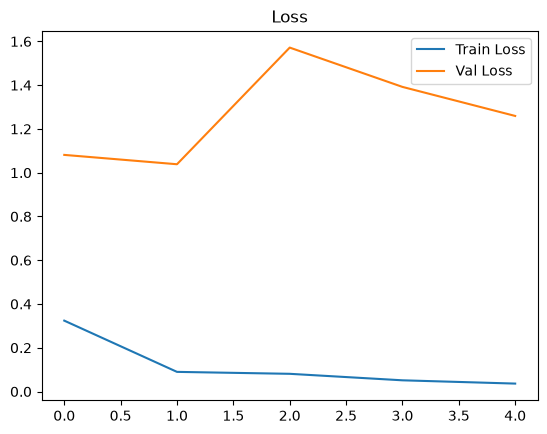

In [14]:
plt.plot(H.history['loss'], label='Train Loss')
plt.plot(H.history['val_loss'], label='Val Loss')
plt.title('Loss')
plt.legend()